In [6]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.nn.functional import cross_entropy
%matplotlib inline

words = open('../names.txt', 'r').read().splitlines()  # 32033
chars = sorted(list(set(''.join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [7]:
block_size = 3


def build_dataset(words):
    X, Y = [], []

    for w in words:
        # fill 3 letters in x fill next in y
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)  # 0.0.0 on first iteration
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


import random

# first we want to shuffle the words
# then we want 80% training set
# then we want 10% dev test
# then we want 10% final test

random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])  # 80%
Xdev, Ydev = build_dataset(words[n1:n2])  # 10%
Xte, Yte = build_dataset(words[n2:])  # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [8]:
# MLP revisited
n_embd = 10  # the dimensionality of the character embedding vectors
n_hidden = 200

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd), generator=g)
W1 = (torch.randn((n_embd * block_size, n_hidden), generator=g)
      * (5 / 3) / ((n_embd * block_size) ** 0.5))
# b1 = torch.randn(n_hidden, generator=g) * 0 - this bias has no actual effect - normalization erases the shift
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.1
b2 = torch.randn(vocab_size, generator=g) * 0

# Batch normalization parameters
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
# two buffers - not trained using backprop - later be used in inference
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, W2, b2, bngain, bnbias]

print(sum(p.nelement() for p in parameters))  # 12297
for p in parameters:
    p.requires_grad = True

12097


In [9]:
gain = 1
class Linear: # https://docs.pytorch.org/docs/2.14/generated/torch.nn.Linear.html#torch.nn.Linear

    def __init__(self, fan_in, fan_out, bias=True):
        self.weight = torch.randn((fan_in, fan_out), generator=g)# / fan_in**0.5
        # W1 = (torch.randn((n_embd * block_size, n_hidden), generator=g)
      # * (5 / 3) / ((n_embd * block_size) ** 0.5))
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        print("layer shape:",self.out.shape)
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])

class BatchNorm1d: # https://docs.pytorch.org/docs/2.14/generated/torch.nn.BatchNorm1d.html

    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True

        #parameters (trained with backprop)
        self.scale = torch.ones(dim) # gamma
        self.shift = torch.zeros(dim) # beta

        #buffers (trained with a running 'momentum update')
        self.running_mean = torch.zeros(dim)
        self.running_variance = torch.ones(dim)

    def __call__(self, x):
        # calculate the forward pass
        if self.training:
            xmean = x.mean(0, keepdim=True)
            xvariance = x.var(0, keepdim=True)
        else:
            xmean = self.running_mean
            xvariance = self.running_variance

        x_normalized = (x-xmean)/torch.sqrt(xvariance + self.eps)
        self.out = self.scale * x_normalized + self.shift

        # update the buffers
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_variance = (1-self.momentum)*self.running_variance + self.momentum * xvariance

        return self.out

    def parameters(self):
        return [self.scale, self.shift]

class Tanh: # https://docs.pytorch.org/docs/2.14/generated/torch.nn.Tanh.html

    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []

n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embd), generator=g)

layers = [
  Linear(n_embd * block_size, n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden), Tanh(),
  Linear(           n_hidden, vocab_size),
]

with torch.no_grad():
    # last layer: make less confident - fix initial loss
    layers[-1].weight *= 0.1
    # all other layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= gain #5/3 # if we don't use a gain you can see in the graph that it's shrinking

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print("total param count: ", sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

total param count:  46497


In [10]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    x = emb.view(emb.shape[0], -1) # concatenate the vectors
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb) # loss function

    # backward pass
    for layer in layers:
        layer.out.retain_grad() # After_debug: would take out retain_graph?
    for p in parameters:
        p.grad = None
    loss.backward()

    # update using stochastic gradient descents
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0: # print every once in a while
        print(f'{i:7d}/{max_steps:7d}:{loss.item():.4f}')
    lossi.append(loss.log10().item())

    break # AFTER_DEBUG: would take out obviously to run full optimization



layer shape: torch.Size([32, 100])
layer shape: torch.Size([32, 100])
layer shape: torch.Size([32, 100])
layer shape: torch.Size([32, 100])
layer shape: torch.Size([32, 100])
layer shape: torch.Size([32, 27])
      0/ 200000:3.5496


layer 0 (    Linear): mean -0.13, std 5.42, saturated: 84.81%
layer 2 (    Linear): mean -0.07, std 9.02, saturated: 92.00%
layer 4 (    Linear): mean +0.01, std 9.64, saturated: 92.00%
layer 6 (    Linear): mean +0.02, std 9.48, saturated: 92.34%
layer 8 (    Linear): mean -0.44, std 9.64, saturated: 92.22%


/var/folders/5x/n7ht8pyj0jj1fl2v5xxqm2lc0000gn/T/ipykernel_3681/2267856510.py:10: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:837.)
  'layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%'


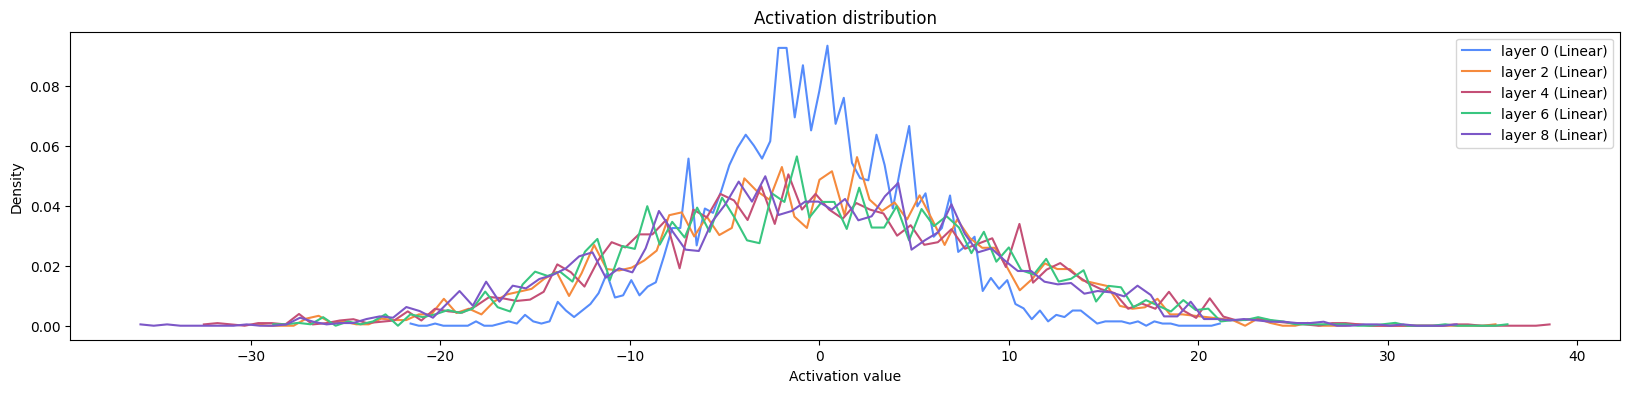

In [11]:
# Visualize activation histograms
plt.figure(figsize=(20, 4))  # Plot width and height
legends = []

for i, layer in enumerate(layers[:-1]):  # Exclude the output layer
    if isinstance(layer, Linear):
        t = layer.out  # Activations produced by this Tanh layer

        print(
            'layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%'
            % (
                i,
                layer.__class__.__name__,
                t.mean(),
                t.std(),
                (t.abs() > 0.97).float().mean() * 100
            )
        )

        # Calculate the activation histogram
        hy, hx = torch.histogram(t, density=True)

        # Plot the histogram
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__})')

plt.legend(legends)
plt.title('Activation distribution')
plt.xlabel('Activation value')
plt.ylabel('Density')
plt.show()

**Rewrite: why saturation goes 67% → 82% with no fan-in scaling**

A neuron multiplies its inputs by its weights and adds those products. Those products are random, mean about 0. They partly cancel, but the leftover drift grows like **√(how many products)**. 30 products → typical size about 5.5. 100 products → typical size about 10.

Look at **one example, one neuron**:

- **32** is how many examples are in the batch. Each example has its own row. It does not go into the sum.
- **100** (the second size of `W`) is how many neurons sit side by side. Each neuron does its own sum. It does not go into one neuron's sum.
- **fan_in** is how many products one neuron adds. Layer 1: 3 letters × 10 embedding numbers = **30**. Layer 2: **100** tanh outputs. That is the number that grows the spread.

Layer 1: `(32, 30) @ (30, 100) → (32, 100)`. One row, one neuron = 30 products added up. Pre-activation std ≈ 5.4. After tanh, about 67% of values sit near ±1.

Layer 2: `(32, 100) @ (100, 100) → (32, 100)`. One row, one neuron = 100 products added up. Pre-activation std ≈ 9. After tanh, about 82% sit near ±1. Later layers stay there because tanh is already almost all ±1.

**The fix:** at init, `weight = randn(fan_in, fan_out) / √fan_in`. Each product is smaller by √fan_in, so 30 products (or 100) add up to typical size **about 1**. The sum is not clipped into [-1, 1]; its spread stays around 1, so tanh stays on the slope.

`fan_in` is the input count of **one neuron** (30, then 100). It is the √ of that count, not the raw count, and not the whole layer's parameter count (30×100 = 3000).

In [ ]:
# one example, one neuron — what 32, 30, 100 are
print('batch Xb', Xb.shape)            # (32, 3)  32 examples, 3 letter ids
print('emb of batch', C[Xb].shape)     # (32, 3, 10)
print('glued batch', C[Xb].view(32, -1).shape)  # (32, 30)
print('layer 1 W', layers[0].weight.shape)      # (30, 100)  fan_in=30, 100 neurons
print('layer 1 out', layers[0].out.shape)       # (32, 100)
print('layer 2 W', layers[2].weight.shape)      # (100, 100) fan_in=100, 100 neurons
print('layer 2 out', layers[2].out.shape)       # (32, 100)
print()

# example 0, neuron 0, layer 1: 30 products → 1 sum
glued0 = C[Xb[0]].view(-1)                      # 30 numbers in hand
terms1 = glued0 * layers[0].weight[:, 0]        # 30 products
s1 = terms1.sum()
print('layer 1 neuron 0: n_terms', terms1.numel(), 'sum', round(s1.item(), 2),
      'matches out[0,0]', round(layers[0].out[0, 0].item(), 2))

# example 0, neuron 0, layer 2: 100 products → 1 sum
h0 = layers[1].out[0]                           # 100 tanh numbers in hand
terms2 = h0 * layers[2].weight[:, 0]            # 100 products
s2 = terms2.sum()
print('layer 2 neuron 0: n_terms', terms2.numel(), 'sum', round(s2.item(), 2),
      'matches out[0,0]', round(layers[2].out[0, 0].item(), 2))
print()

# coin fact: more terms → bigger typical |sum|
g2 = torch.Generator().manual_seed(0)
print('n_terms | sum std | sqrt(n)')
for n in [1, 4, 30, 100]:
    sums = torch.randn(2000, n, generator=g2).sum(1)
    print(f'{n:7d} | {sums.std().item():7.2f} | {n**0.5:.2f}')
print()
print('same sums after /sqrt(n) on the weights — std stays ~1')
for n in [1, 4, 30, 100]:
    x = torch.randn(2000, n, generator=g2)
    w = torch.randn(2000, n, generator=g2) / n**0.5
    sums = (x * w).sum(1)
    print(f'{n:7d} terms  sum std {sums.std().item():.2f}')


layer 1 (      Tanh): mean -0.001858, std 1.175303e-01
layer 3 (      Tanh): mean +0.000711, std 4.413074e-02
layer 5 (      Tanh): mean +0.000358, std 1.852568e-02
layer 7 (      Tanh): mean +0.000175, std 7.418484e-03
layer 9 (      Tanh): mean -0.000149, std 3.128865e-03


Text(0.5, 1.0, 'gradient distribution')

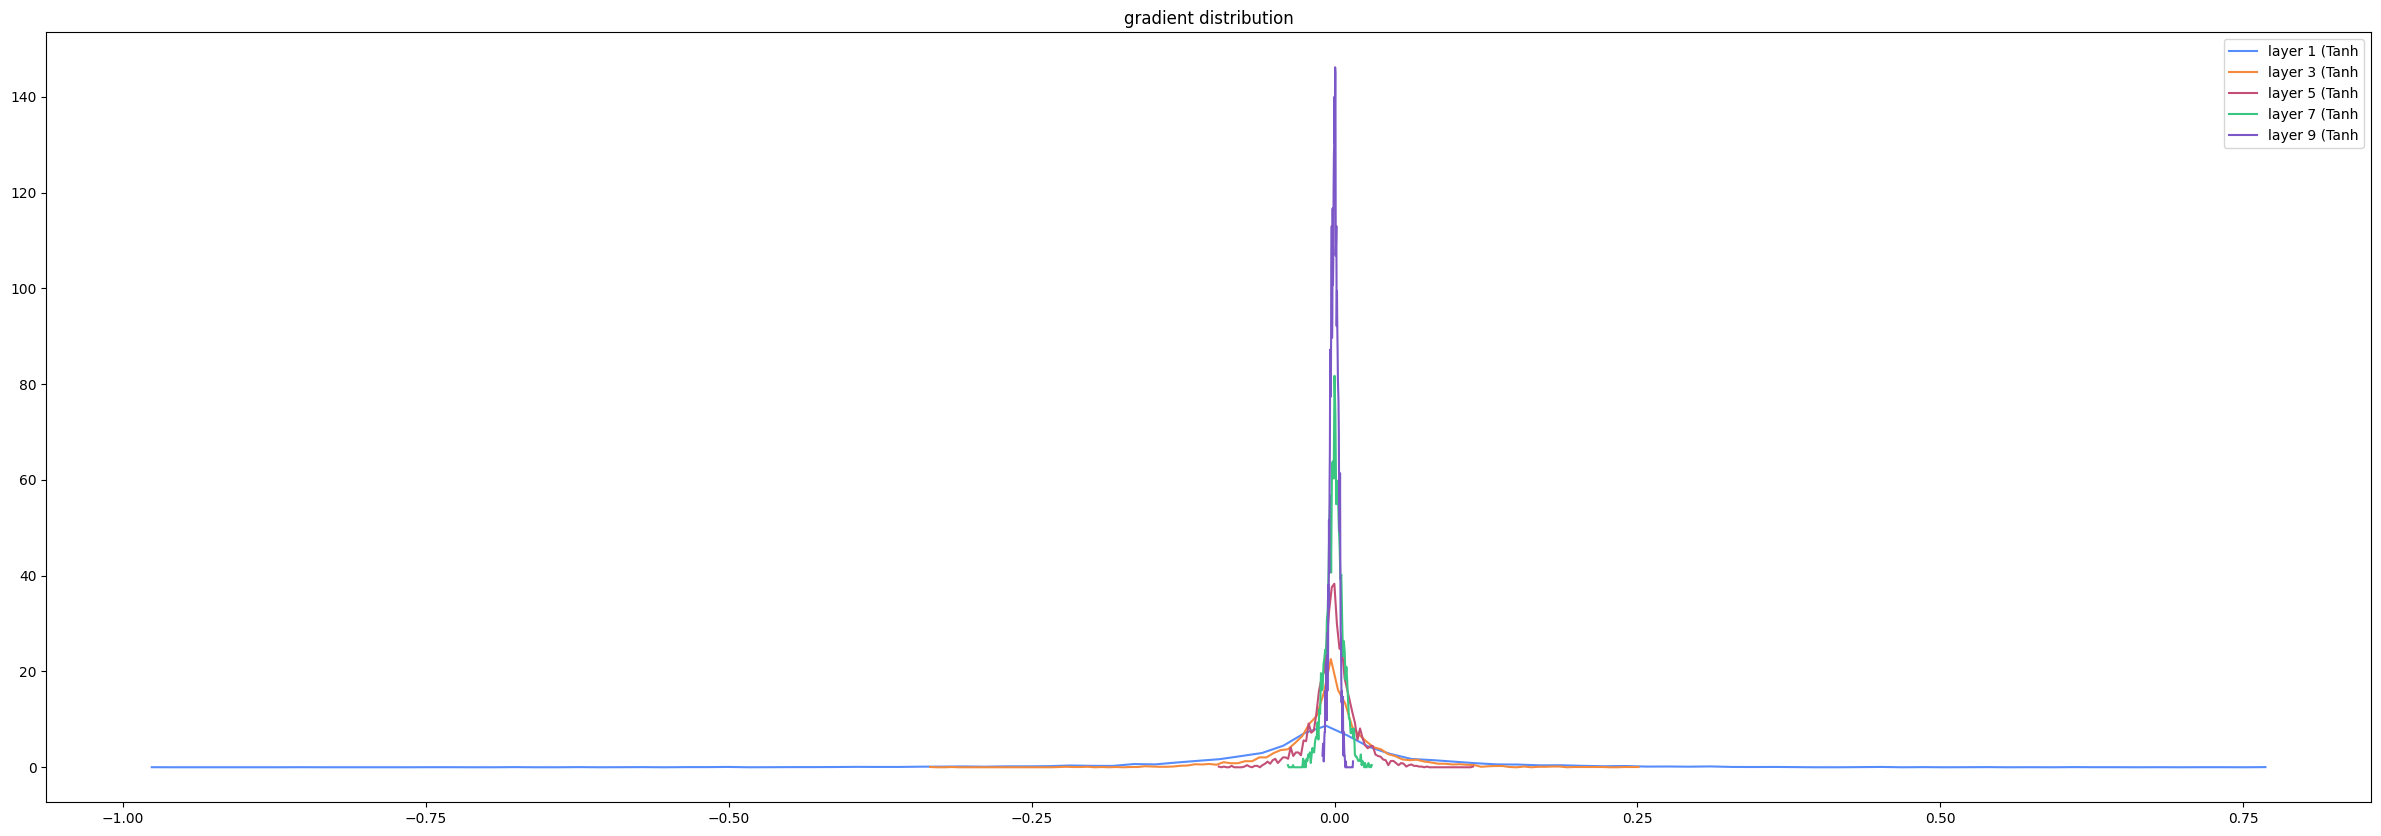

In [12]:
# visualize histograms
plt.figure(figsize=(30, 10))  # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]):  # note: exclude the output layer
    if isinstance(layer, Tanh):
        t = layer.out.grad
        print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')


weight   (27, 10) | mean -0.006318 | std 5.773800e-01 | grad:data ratio 5.756543e-01
weight  (30, 100) | mean +0.001196 | std 1.779697e-01 | grad:data ratio 1.736124e-01
weight (100, 100) | mean -0.000558 | std 6.056067e-02 | grad:data ratio 6.075851e-02
weight (100, 100) | mean -0.000192 | std 2.466996e-02 | grad:data ratio 2.449104e-02
weight (100, 100) | mean -0.000023 | std 1.045396e-02 | grad:data ratio 1.042175e-02
weight (100, 100) | mean +0.000037 | std 4.007000e-03 | grad:data ratio 3.990790e-03
weight  (100, 27) | mean -0.000000 | std 3.369801e-02 | grad:data ratio 3.415715e-01


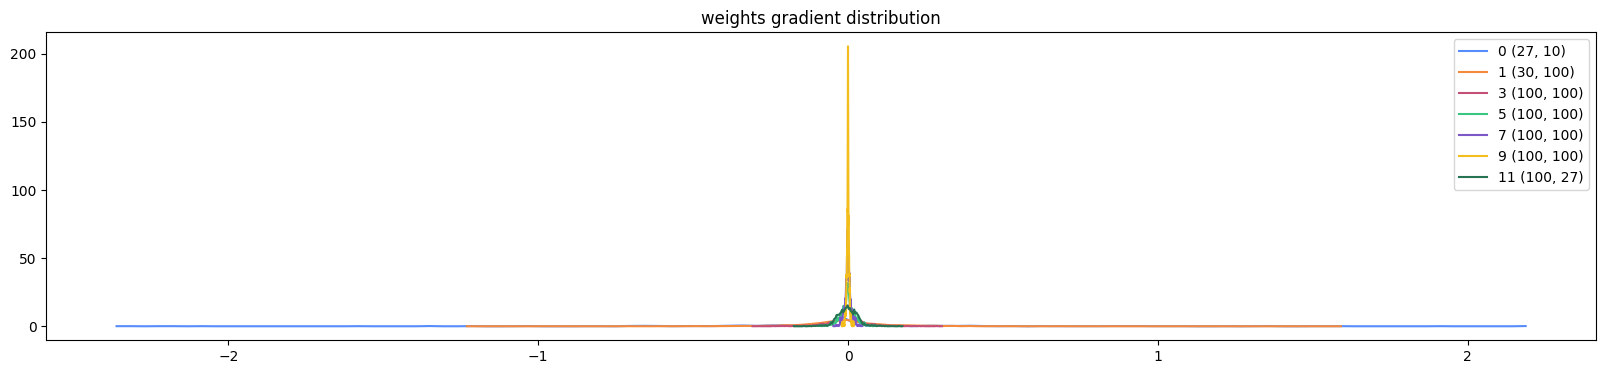

In [13]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

In [14]:
# plt.figure(figsize=(20, 4))
# legends = []
# for i,p in enumerate(parameters):
#   if p.ndim == 2:
#     plt.plot([ud[j][i] for j in range(len(ud))])
#     legends.append('param %d' % i)
# plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
# plt.legend(legends);


In [15]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  x = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, y)
  print(split, loss.item())

# put layers into eval mode
for layer in layers:
  layer.training = False
split_loss('train')
split_loss('val')

layer shape: torch.Size([182625, 100])
layer shape: torch.Size([182625, 100])
layer shape: torch.Size([182625, 100])
layer shape: torch.Size([182625, 100])
layer shape: torch.Size([182625, 100])
layer shape: torch.Size([182625, 27])
train 3.747814893722534
layer shape: torch.Size([22655, 100])
layer shape: torch.Size([22655, 100])
layer shape: torch.Size([22655, 100])
layer shape: torch.Size([22655, 100])
layer shape: torch.Size([22655, 100])
layer shape: torch.Size([22655, 27])
val 3.739900827407837


In [16]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass the neural net
      emb = C[torch.tensor([context])] # (1,block_size,n_embd)
      x = emb.view(emb.shape[0], -1) # concatenate the vectors
      for layer in layers:
        x = layer(x)
      logits = x
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break

    print(''.join(itos[i] for i in out)) # decode and print the generated word

layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 27])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 27])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 27])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 27])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch.Size([1, 100])
layer shape: torch

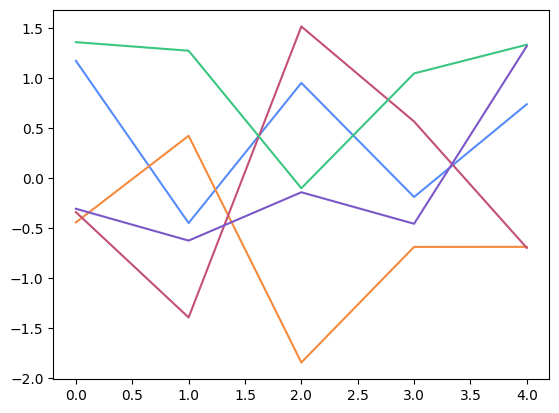

In [17]:
weighta = torch.randn((5, 5), generator=g)# / fan_in**0.5
plt.plot(weighta)

tensor([[-0.4057, -0.3212, -0.3832, -0.1621, -0.4621],
        [-0.0739, -0.1067,  0.3688,  0.1849, -0.2892],
        [-0.4284, -0.1223,  0.6805, -0.1229, -0.0725],
        [-0.0475, -0.1849,  0.5592,  0.6140,  0.5606],
        [ 0.0170,  0.5835,  1.0001, -0.2229,  0.8591]])


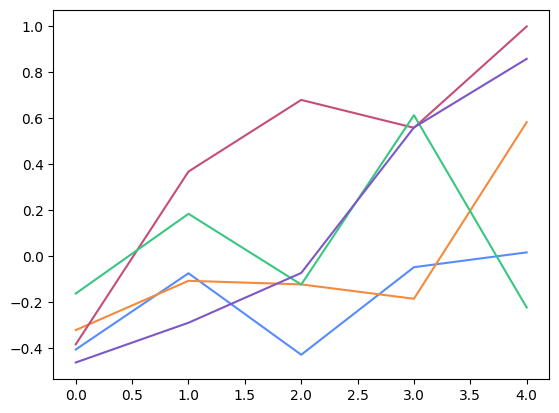

In [18]:
weighta = torch.randn((5, 5), generator=g) / 5**0.5
plt.plot(weighta)
print(weighta)